In [1]:
# Import required libraries
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils import resample
import numpy as np

In [2]:
# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

model = DecisionTreeClassifier(random_state=42)

In [3]:
# 1. Bootstrapping
bootstrap_accuracy = []
bootstrap_f1 = []

for i in range(100):
    # Generate bootstrap sample
    X_sample, y_sample = resample(
        X, y, replace=True, random_state=i
    )

    # Find samples not selected in the bootstrap sample
    selected = set(resample(
        np.arange(len(X)), replace=True,
        n_samples=len(X), random_state=i
    ))
    test_indices = [j for j in range(len(X)) if j not in selected]

    if len(test_indices) == 0:
        continue

    model.fit(X_sample, y_sample)

    y_pred = model.predict(X[test_indices])

    bootstrap_accuracy.append(
        accuracy_score(y[test_indices], y_pred)
    )
    bootstrap_f1.append(
        f1_score(y[test_indices], y_pred, average='weighted')
    )

In [4]:
# 2. K-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

accuracy_scores = cross_val_score(
    model, X, y, cv=kf, scoring='accuracy'
)

f1_scores = cross_val_score(
    model, X, y, cv=kf, scoring='f1_weighted'
)

In [5]:
# 3. Display results
print("Bootstrapping Results")
print("Mean Accuracy:", np.mean(bootstrap_accuracy))
print("Mean F1-Score:", np.mean(bootstrap_f1))

print("\nK-Fold Cross-Validation Results")
print("Mean Accuracy:", np.mean(accuracy_scores))
print("Mean F1-Score:", np.mean(f1_scores))

Bootstrapping Results
Mean Accuracy: 0.9472491624797581
Mean F1-Score: 0.9471448741098973

K-Fold Cross-Validation Results
Mean Accuracy: 0.9533333333333335
Mean F1-Score: 0.9531851481851483


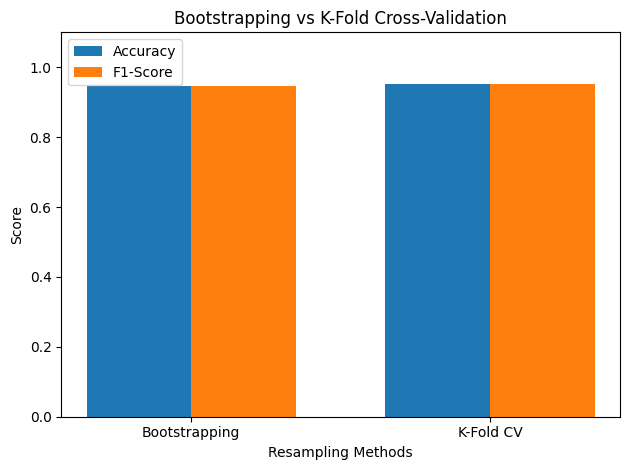

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate average performance metrics
accuracy = [np.mean(bootstrap_accuracy), np.mean(accuracy_scores)]
f1 = [np.mean(bootstrap_f1), np.mean(f1_scores)]

# Bar graph
methods = ['Bootstrapping', 'K-Fold CV']
x = np.arange(len(methods))
width = 0.35

plt.bar(x - width/2, accuracy, width, label='Accuracy')
plt.bar(x + width/2, f1, width, label='F1-Score')

plt.xlabel('Resampling Methods')
plt.ylabel('Score')
plt.title('Bootstrapping vs K-Fold Cross-Validation')
plt.xticks(x, methods)
plt.ylim(0, 1.1)
plt.legend()

plt.tight_layout()
plt.show()